# Day 3: Your first real EEG data in Python (MNE)

**Today's goal:** load real EEG from a real person, clean it, and reproduce one of the oldest findings in neuroscience: **alpha waves (8–12 Hz) get stronger when you close your eyes.** Hans Berger, the inventor of EEG, first saw this in 1929.

**Why this matters for you:** these are the same steps you did in MATLAB for your MSc (load, filter, re-reference, power spectrum). Today you learn to do them in Python with **MNE**, the most widely used free EEG toolbox. Your Parkinson's project will use exactly this pipeline.

**How to use this notebook:** read the text box, then run the code box under it with **Shift + Enter**. Each code box has `#` comments explaining every line.

## Step 1: Bring in the tools

**What:** `import` loads a toolbox so Python can use it, like taking tools out of a drawer.

**Why:** Python starts with almost nothing. We add what we need:
- `mne`: the EEG toolbox
- `numpy` (shortened to `np`): maths on big lists of numbers
- `matplotlib.pyplot` (shortened to `plt`): drawing graphs

In [1]:
import mne                      # the EEG toolbox
import numpy as np              # number crunching
import matplotlib.pyplot as plt # drawing graphs
from mne.datasets import eegbci # a free public EEG dataset that comes with MNE

mne.set_log_level('WARNING')    # makes MNE print fewer messages, so the output is easier to read
print('MNE version:', mne.__version__)

MNE version: 1.13.2


## Step 2: Download real EEG data

**What:** we download recordings from a public dataset called **EEG Motor Movement/Imagery** (PhysioNet). 109 volunteers wore a **64-channel EEG cap**.

We take **person 1**, two 1-minute recordings:
- **Run 1:** sitting still, **eyes open**
- **Run 2:** sitting still, **eyes closed**

**Why a public dataset?** Anyone in the world can download the same files and check your results. This is called **open science**, and it is exactly what your solo project will do.

The download is about 5 MB and happens only once. The files are saved in a folder called `mne_data` in your home folder.

In [2]:
# load_data downloads the files (if needed) and gives back where they are saved
files = eegbci.load_data(subjects=[1], runs=[1, 2], update_path=False)

print('Eyes open file:  ', files[0])
print('Eyes closed file:', files[1])

Eyes open file:   /Users/ujaifa/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf
Eyes closed file: /Users/ujaifa/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R02.edf


## Step 3: Open the eyes-open recording

**What:** `read_raw_edf` opens an EEG file. `.edf` is a common EEG file format, a bit like `.docx` is for Word.

MNE puts the recording into a **Raw** object. Think of it as a giant spreadsheet:
- **rows** = channels (electrodes on the head), 64 here
- **columns** = moments in time

`preload=True` means "load all the data into memory now", which we need before we can filter it.

In [3]:
raw_open = mne.io.read_raw_edf(files[0], preload=True)

# .info is the recording's 'ID card': channels, sampling rate, etc.
print('Number of channels:', len(raw_open.ch_names))
print('Sampling rate:', raw_open.info['sfreq'], 'Hz  (= measurements per second)')
print('Length:', round(raw_open.times[-1]), 'seconds')
print('First 5 channel names:', raw_open.ch_names[:5])

Number of channels: 64
Sampling rate: 160.0 Hz  (= measurements per second)
Length: 61 seconds
First 5 channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.']


**Understanding the output:**
- **Sampling rate 160 Hz** means the EEG measured each electrode 160 times every second. Your MSc data was 250 Hz.
- The channel names look odd (`Fc5.`, `C3..`) because this old dataset added dots. We fix that next.

## Step 4: Fix channel names and tell MNE where each electrode sits

**What:**
1. `standardize` cleans the names (`C3..` becomes `C3`).
2. `set_montage` tells MNE the position of each electrode on the head, using the standard **10-20 system** (the same system as your MSc caps).

**Why:** without positions, MNE doesn't know that O1 is at the back of the head and Fp1 is at the front. We need positions to draw head maps.

Clean names: ['FC5', 'FC3', 'FC1', 'FCz', 'FC2']


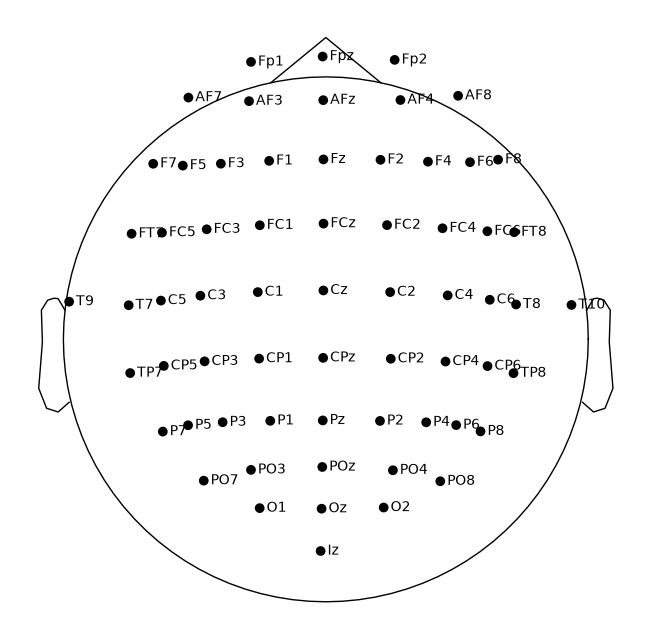

In [4]:
eegbci.standardize(raw_open)              # clean up the channel names
raw_open.set_montage('colin27_1005')     # attach standard electrode positions

print('Clean names:', raw_open.ch_names[:5])

# draw where the electrodes are (seen from above, nose at the top)
raw_open.plot_sensors(show_names=True)
plt.show()

## Step 5: Look at the raw EEG

**What:** plot 10 seconds of 20 channels, like scrolling through the EEG in EEGLAB.

**Why:** **always look at your data first.** Real EEG has slow drifts, sudden jumps and noise. Looking first stops you analysing rubbish.

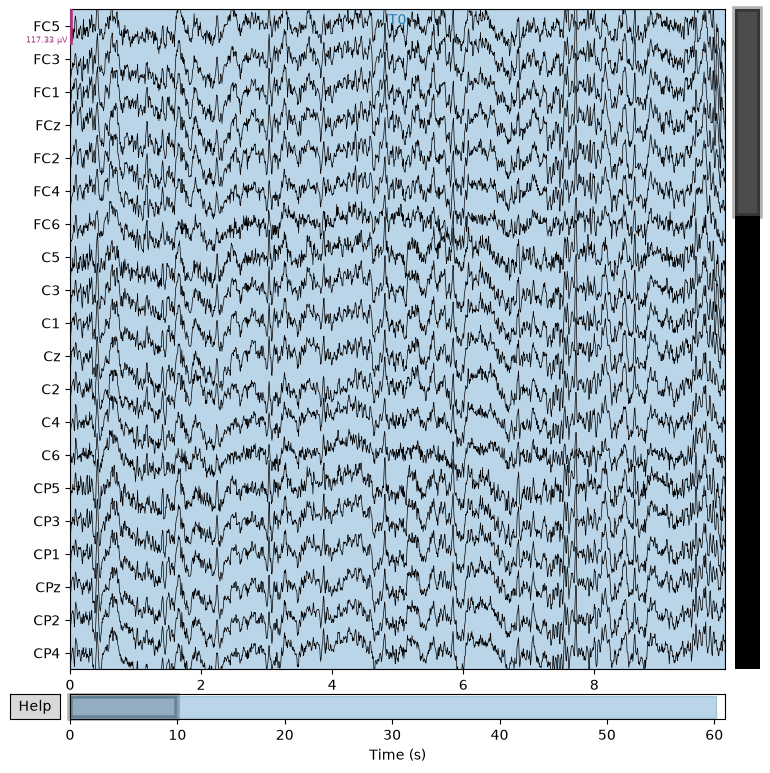

In [6]:
raw_open.plot(duration=10, n_channels=20, scalings='auto')
plt.show()

## Step 6: Clean the signal with a filter

**What:** a **band-pass filter** from **1 to 40 Hz** keeps brain rhythms between 1 and 40 Hz and removes the rest.

**Why:**
- **Below 1 Hz:** slow drifts from sweat and the cap moving, not brain activity.
- **Above 40 Hz:** mostly muscle noise and electrical noise from the mains (60 Hz in the USA, where this data was recorded; 50 Hz in the UK).
- The rhythms we care about, **alpha (8–12 Hz)** and **beta (13–30 Hz)**, sit safely inside 1–40 Hz.

You did exactly this in MATLAB for your MSc.

In [7]:
raw_open.filter(l_freq=1.0, h_freq=40.0)   # l_freq = low cut-off, h_freq = high cut-off
print('Filtered between 1 and 40 Hz')

Filtered between 1 and 40 Hz


## Step 7: Re-reference to the average

**What:** EEG always measures the voltage **difference** between each electrode and a reference point. **Average reference** subtracts the average of all electrodes from each one.

**Why:** it removes signals that appear on *every* electrode equally (often noise), and it is the standard choice for high-density caps like this 64-channel one.

In [9]:
raw_open.set_eeg_reference('average')
print('Re-referenced to the average of all electrodes')

Re-referenced to the average of all electrodes


## Step 8: The power spectrum (which rhythms are strongest?)

**What:** a **power spectrum** (PSD) answers: *how much of each frequency is in the signal?*

Imagine the EEG is a song. The spectrum tells you how loud each note is. The x-axis is the frequency (the note) and the y-axis is the power (how loud).

**What to look for:** the line generally slopes down (low frequencies are always stronger; this is the **1/f** or **aperiodic** part). Any **bump** sticking up is a real brain rhythm. Look for a bump around **10 Hz**: that's alpha.

**Why this matters for your project:** separating the bumps from the sloping background is exactly what **specparam** does. That's the core of your Parkinson's study.

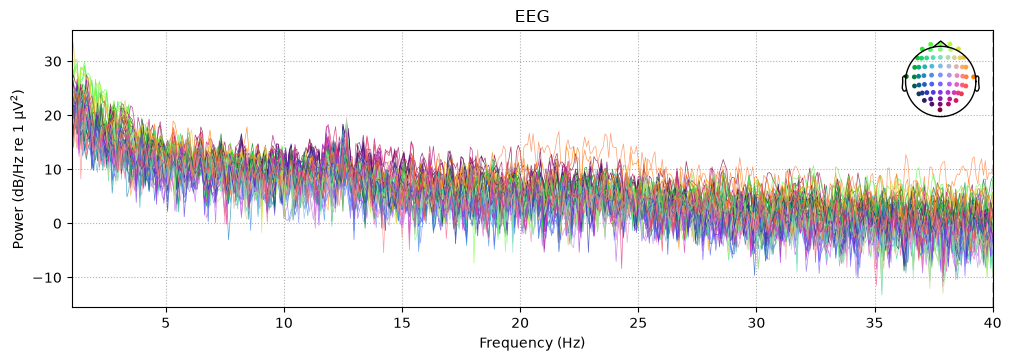

In [10]:
spectrum_open = raw_open.compute_psd(fmin=1, fmax=40)   # compute the power spectrum
spectrum_open.plot()                                    # one line per channel
plt.show()

## Step 9: Do the same for eyes closed, using a function

**What:** instead of copying Steps 3–7 again, we put them in a **function**, a reusable recipe. We write it once and use it for any file.

**Why:** in your real project you'll process 50+ people. Functions mean you write the steps once and avoid copy-paste mistakes. This is the most important habit in research coding.

**How to read it:**
- `def preprocess(path):` means "here's a recipe called preprocess, and it needs a file path".
- The indented lines are the steps.
- `return raw` hands the cleaned data back.

In [11]:
def preprocess(path):
    """Load an EEGBCI file and apply the same cleaning steps as above."""
    raw = mne.io.read_raw_edf(path, preload=True)
    eegbci.standardize(raw)
    raw.set_montage('colin27_1005')
    raw.filter(l_freq=1.0, h_freq=40.0)
    raw.set_eeg_reference('average')
    return raw

raw_closed = preprocess(files[1])   # use the recipe on the eyes-closed file
print('Eyes-closed data ready:', len(raw_closed.ch_names), 'channels')

Eyes-closed data ready: 64 channels


## Step 10: Compare eyes open vs eyes closed at the back of the head

**What:** alpha is strongest over the **occipital** lobe (back of the head, which handles vision), so we use electrodes **O1, Oz and O2**. We compute the spectrum for both conditions, average the three electrodes, and plot them on top of each other.

**Expected result:** the **eyes-closed** line should show a much bigger bump at about 10 Hz. When the eyes close, the visual cortex idles, and idling shows up as strong alpha.

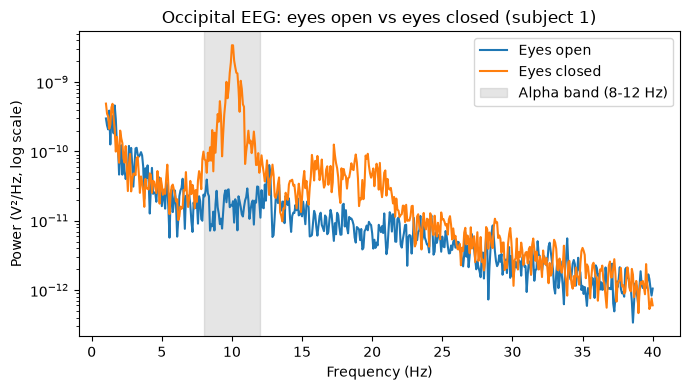

In [12]:
occipital = ['O1', 'Oz', 'O2']   # electrodes at the back of the head

def occipital_spectrum(raw):
    """Return frequencies and the average power over O1, Oz, O2."""
    spec = raw.compute_psd(fmin=1, fmax=40, picks=occipital)
    power, freqs = spec.get_data(return_freqs=True)   # power: one row per channel
    return freqs, power.mean(axis=0)                  # average the 3 channels

freqs, power_open   = occipital_spectrum(raw_open)
freqs, power_closed = occipital_spectrum(raw_closed)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(freqs, power_open,   label='Eyes open')     # semilogy = log scale on y-axis
ax.semilogy(freqs, power_closed, label='Eyes closed')
ax.axvspan(8, 12, color='grey', alpha=0.2, label='Alpha band (8-12 Hz)')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power (V²/Hz, log scale)')
ax.set_title('Occipital EEG: eyes open vs eyes closed (subject 1)')
ax.legend()
plt.tight_layout()
plt.show()

## Step 11: Put a number on it

**What:** average the power inside 8–12 Hz for each condition and divide one by the other.

**Why:** graphs convince people, but papers need numbers. A ratio above 1 means more alpha with eyes closed.

In [14]:
alpha = (freqs >= 8) & (freqs <= 12)        # True for frequencies inside the alpha band

alpha_open   = power_open[alpha].mean()
alpha_closed = power_closed[alpha].mean()

print(f'Alpha power, eyes open:   {alpha_open:.2e}')
print(f'Alpha power, eyes closed: {alpha_closed:.2e}')
print(f'Eyes closed / eyes open:  {alpha_closed / alpha_open:.1f} times stronger')

Alpha power, eyes open:   1.80e-11
Alpha power, eyes closed: 5.53e-10
Eyes closed / eyes open:  30.7 times stronger


## Step 12: Where on the head is alpha strongest? (topographic map)

**What:** a **topomap** colours the head by alpha power at each electrode. It's the head-shaped heat maps you see in EEG papers.

**Expected:** with eyes closed, the hottest colours should be at the **back of the head**.

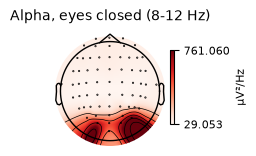

In [15]:
spectrum_closed = raw_closed.compute_psd(fmin=1, fmax=40)
spectrum_closed.plot_topomap(bands={'Alpha, eyes closed (8-12 Hz)': (8, 12)})
plt.show()

## What you learned today

| Step | MNE command | Why |
|---|---|---|
| Load | `mne.io.read_raw_edf()` | open an EEG file |
| Positions | `set_montage()` | know where electrodes are |
| Filter | `raw.filter(1, 40)` | remove drifts and noise |
| Re-reference | `set_eeg_reference('average')` | remove shared noise |
| Spectrum | `compute_psd()` | how strong each rhythm is |
| Function | `def preprocess():` | reuse the same steps for every person |

**Glossary**
- **Raw**: MNE's container for continuous EEG.
- **Sampling rate**: measurements per second.
- **PSD (power spectral density)**: how much power at each frequency.
- **Alpha / beta**: 8–12 Hz / 13–30 Hz brain rhythms.
- **Aperiodic (1/f)**: the downward-sloping background of the spectrum.
- **Topomap**: head-shaped colour map.

## Mini challenge (do this yourself)
1. Copy the Step 10 code into a new box, change `occipital` to `['C3', 'Cz', 'C4']` (motor cortex), and the shaded band to **13–30 Hz (beta)**. Does beta change between eyes open and closed?
2. Change `subjects=[1]` to `subjects=[2]` in Step 2 and re-run everything. Does person 2 show the same alpha effect?

**Finally:** save (**Cmd + S**), then in **Source Control**, type the message `Day 3: first EEG analysis in MNE` → **Commit** → **Sync Changes**.

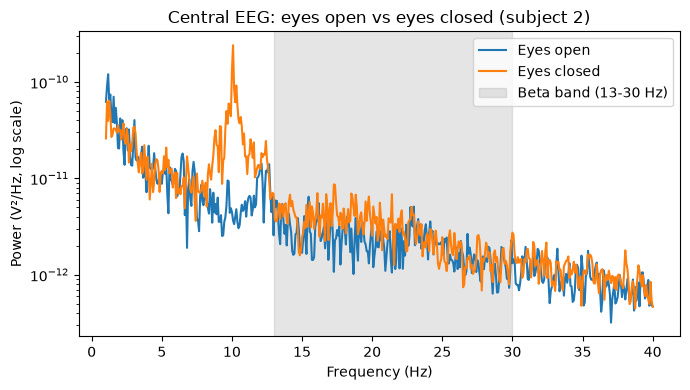

In [20]:
occipital = ['C3', 'Cz', 'C4']   # electrodes at the back of the head

def occipital_spectrum(raw):
    """Return frequencies and the average power over O1, Oz, O2."""
    spec = raw.compute_psd(fmin=1, fmax=40, picks=occipital)
    power, freqs = spec.get_data(return_freqs=True)   # power: one row per channel
    return freqs, power.mean(axis=0)                  # average the 3 channels

freqs, power_open   = occipital_spectrum(raw_open)
freqs, power_closed = occipital_spectrum(raw_closed)

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(freqs, power_open,   label='Eyes open')     # semilogy = log scale on y-axis
ax.semilogy(freqs, power_closed, label='Eyes closed')
ax.axvspan(13, 30, color='grey', alpha=0.2, label='Beta band (13-30 Hz)')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power (V²/Hz, log scale)')
ax.set_title('Central EEG: eyes open vs eyes closed (subject 2)')
ax.legend()
plt.tight_layout()
plt.show()